# Import Environment variables

In [1]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.ipynb

Found bucket: id=rw-migration-aou-rw-f7a4d148, bucketName=rw-migration-aou-rw-f7a4d148
-> Assigned migration variables (ID: rw-migration-aou-rw-f7a4d148)
Found bucket: id=temporary-workspace-bucket, bucketName=temporary-workspace-bucket-wb-perky-cabbage-8342
Found bucket: id=workspace-bucket, bucketName=workspace-bucket-wb-perky-cabbage-8342
✅ Successfully identified latest dataset: wb-silky-artichoke-2408.C2024Q3R9

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-perky-cabbage-8342
WORKSPACE_BUCKET: gs://workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_TEMP_BUCKET: gs://temporary-workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9
bucket_aou_tutorial: NOT FOUND
bucket_id_aou_tutorial: NOT FOUND
bucket_migrated: gs://rw-migration-aou-rw-f7a4d148
bucket_id_migrated: rw-migration-aou-rw-f7a4d148

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
Multi-trait-GWAS-in-admixed-populations GIT_REPO
dataset_test2 BQ_DATASET
prep_C2024Q3R9 BQ_DATASET
rw-mig

In [2]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.ipynb

WORKSPACE_CDR = wb-silky-artichoke-2408.C2024Q3R9
WORKSPACE_BUCKET = gs://workspace-bucket-wb-perky-cabbage-8342
GOOGLE_PROJECT = wb-perky-cabbage-8342
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.R
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.sas


# Librairy

In [3]:
import os
import numpy as np
import pandas as pd

# Data's import

## PRS 298, 305 et 311

In [4]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_all_prs_298_305_311.csv"

df_prs = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## Clinical data

In [5]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_bc_ko_at_inclusion_223k_nb_BC_WITHIN_5Y_GeneticAncestry_biopsy_FamilyHistory_LastSelection.tsv"

df = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [6]:
df.drop(columns=['gender','date_of_birth','ethnicity','self_reported_category','time_category','delay_years',
                 'first_any_biopsy_date','days_inclusion_to_biopsy', 'days_biopsy_to_cancer',
                 'first_survey_date', 'last_survey_date','days_last_survey_to_first_survey', 'days_inclusion_to_first_survey',
                 'days_inclusion_to_last_survey', 'days_has_bc_to_first_survey','days_has_bc_to_last_survey',
                 'date_1_of_biopsy_19081_19086', 'date_2_of_biopsy_19081_19086', 'date_3_of_biopsy_19081_19086',
                 'has_biopsy_19081_19086',
                 'date_1_of_biopsy_19100_19103', 'date_2_of_biopsy_19100_19103', 'date_3_of_biopsy_19100_19103',
                 'has_biopsy_19100_19103',
                 'date_1_of_biopsy_19120_19125_19126', 'date_2_of_biopsy_19120_19125_19126', 'date_3_of_biopsy_19120_19125_19126',
                 'has_biopsy_19120_19125_19126',
                 'Daughter', 'Mother', 'Sibling',
                 'statut_parente'], inplace=True)

In [7]:
df.columns

Index(['person_id', 'inclusion_date', 'first_breast_cancer_date', 'delay_days',
       'age_at_inclusion', 'has_bc', 'eur_rye', 'eas_rye', 'amr_rye',
       'afr_rye', 'sas_rye', 'mid_rye', 'dominant_origin', 'ancestry_80',
       'biopsy_result', 'age_category', 'race_us_bcsc', 'race_us_bcsc_detail',
       'breast_cancer_family_history_first_degree'],
      dtype='object')

### Selection des femmes européennes

In [8]:
df[df['race_us_bcsc_detail'] == 'eur_rye'].value_counts('has_bc')

has_bc
0    73120
1      464
Name: count, dtype: int64

In [9]:
df_eur = df[df['race_us_bcsc_detail'] == 'eur_rye'].copy()

# Data set merged

In [10]:
df_models = pd.merge(df_eur, df_prs, left_on='person_id', right_on='index', how='left')

# Split de la cohorte européenne

In [11]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "train_ids_eur.csv"

train_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [12]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "test_ids_eur.csv"

test_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

# Evaluation de performance des PRS

In [13]:
df_models.columns

Index(['person_id', 'inclusion_date', 'first_breast_cancer_date', 'delay_days',
       'age_at_inclusion', 'has_bc', 'eur_rye', 'eas_rye', 'amr_rye',
       'afr_rye', 'sas_rye', 'mid_rye', 'dominant_origin', 'ancestry_80',
       'biopsy_result', 'age_category', 'race_us_bcsc', 'race_us_bcsc_detail',
       'breast_cancer_family_history_first_degree', 'index', 'prs_298',
       'risk_ratio_298', 'num_snps_with_genotypes_298', 'num_snps_total_298',
       'prs_305', 'risk_ratio_305', 'num_snps_with_genotypes_305',
       'num_snps_total_305', 'prs_311', 'risk_ratio_311',
       'num_snps_with_genotypes_311', 'num_snps_total_311'],
      dtype='object')

## Fonctions

### Fonction d'évaluation brut

**1. Pourquoi un PRS brut ne peut pas s'utiliser directement pour prendre une décision médicale**

Un PRS brut (comme le score $Z$ ou la somme des poids $\beta \cdot G$) n'est qu'un score relatif. Il te dit où se situe une personne par rapport à une moyenne de population, mais il ne donne aucune probabilité absolue de tomber malade (ex. « $12\%$ de risque à 10 ans »).

Or, en clinique ou dans les recommandations (ex. HAS, USPSTF) :

* Les seuils de dépistage précoce ou d'IRM mammaire se basent sur des risques absolus (ex. risque $>20\%$ sur la vie entière).
* Un PRS brut ne possède pas d'unité épidémiologique.

**2. Les 3 cas de figure où la recalibration est nécessaire**
    
**A. Pour l'intégrer à des modèles épidémiologiques (Modèles Hybrides)**

* Si tu veux combiner le PRS-313 avec Mammorisk® ou BCSC v2, tu multiplies les risques relatifs du PRS par l'incidence de base ou les risques prédits par le modèle clinique.
* Si le PRS brut a une moyenne ou un écart-type mal ajusté sur la cohorte cible (ex. dérive due à l'ascendance/admixture dans All of Us), le risque absolu combiné sera complètement biaisé.

**B. Pour corriger le biais d'ascendance (Portabilité)**

* Les poids $\beta$ du PRS-313 ont été appris majoritairement sur des femmes d'ascendance européenne (UK Biobank / BCAC).
* Appliqué directement sur des populations afro-américaines ou hispaniques d' All of Us, la distribution du score décale sa moyenne ($\mu \neq 0$) et sa variance ($\sigma^2 \neq 1$). Recalibrer la moyenne et la variance par groupe d'ascendance est obligatoire pour éviter de sur-estimer ou sous-estimer le risque chez les minorités.

**3. Pour convertir le Z-score en probabilité absolue (Régression logistique avec offset)**

* C'est ce que fait le protocole de Rassy et al. : on fait régresser le Z-score sur le statut cas/témoin dans un jeu d'entraînement (25% Train) pour estimer l'intercept ($\alpha$) et la pente ($\beta_{\text{PRS}}$), afin de transformer le Z-score en probabilités absolues réétalonnées $p \in [0, 1]$.

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import auc, roc_curve


def bootstrap_auc(y_true_ser, y_scores_ser, n_bootstraps=1000, rng_seed=42):
    """Calcule l'intervalle de confiance à 95% de l'AUC-ROC par bootstrap."""
    bootstrapped_scores = []
    rng = np.random.RandomState(rng_seed)
    y_true_arr = np.array(y_true_ser)
    y_scores_arr = np.array(y_scores_ser)

    for _ in range(n_bootstraps):
        indices = rng.randint(0, len(y_scores_arr), len(y_scores_arr))
        if len(np.unique(y_true_arr[indices])) < 2:
            continue
        score = auc(
            *roc_curve(y_true_arr[indices], y_scores_arr[indices])[:2]
        )
        bootstrapped_scores.append(score)

    sorted_scores = np.sort(bootstrapped_scores)
    return sorted_scores[int(0.025 * len(sorted_scores))], sorted_scores[
        int(0.975 * len(sorted_scores))
    ]


def evaluate_and_plot_raw_prs(
    df_data,
    test_ids,
    prs_col="prs_311",
    target_col="has_bc",
    id_col="person_id",
    model_name=None,
    quantiles=None,
    labels=None,
    ref_quantile_idx=2,
    figsize=(16, 6),
):
    """Évalue et trace la capacité de discrimination (ROC) et la stratification par quintile

    d'un Polygenic Risk Score (PRS) brut au choix.
    """
    if model_name is None:
        model_name = f"PRS ({prs_col})"

    if quantiles is None:
        quantiles = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
    if labels is None:
        labels = [
            "Q1 (<20%)",
            "Q2 (20-40%)",
            "Q3 (40-60%)",
            "Q4 (60-80%)",
            "Q5 (>80%)",
        ]

    # 1. Extraction et conversion stricte de test_ids en tableau 1D
    if isinstance(test_ids, (pd.DataFrame, pd.Series)):
        ids_to_match = test_ids.values.ravel()  # Aplatit en array 1D
    else:
        ids_to_match = np.asarray(test_ids).ravel()

    # Sélection du jeu de test
    df_test = df_data[df_data[id_col].isin(ids_to_match)].copy()
    df_eval = df_test.dropna(subset=[target_col, prs_col]).copy()

    y_true = df_eval[target_col]
    prs_scores = df_eval[prs_col]

    # 2. Métriques ROC et AUC
    fpr, tpr, _ = roc_curve(y_true, prs_scores)
    roc_auc = auc(fpr, tpr)
    ci_lower, ci_upper = bootstrap_auc(y_true, prs_scores)

    # 3. Découpage en Quantiles
    df_eval["prs_group"] = pd.qcut(
        df_eval[prs_col], q=quantiles, labels=labels, duplicates="drop"
    )

    # A. Incidence réelle (%)
    incidence = df_eval.groupby("prs_group", observed=False)[target_col].agg(
        ["mean", "count"]
    )
    incidence["pct"] = incidence["mean"] * 100
    incidence = incidence.reindex(labels)

    # B. Odds Ratios par régression logistique
    dummies = pd.get_dummies(df_eval["prs_group"], drop_first=False)
    ref_col = labels[ref_quantile_idx]
    if ref_col not in dummies.columns:
        ref_col = dummies.columns[len(dummies.columns) // 2]

    X = dummies.drop(columns=[ref_col]).astype(int)
    X = sm.add_constant(X)

    logit_mod = sm.Logit(y_true, X).fit(disp=False)
    conf = logit_mod.conf_int()

    or_df = pd.DataFrame(
        {
            "OR": np.exp(logit_mod.params),
            "lower": np.exp(conf[0]),
            "upper": np.exp(conf[1]),
        }
    )
    or_df.loc["const"] = [1.0, 1.0, 1.0]
    or_df.index = [c if c != "const" else ref_col for c in or_df.index]
    or_df = or_df.reindex(labels)

    # 4. Tracé de la Figure
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Subplot 1 : ROC ---
    axes[0].plot(
        fpr,
        tpr,
        color="darkorange",
        lw=2,
        label=(
            f"{model_name} (AUC = {roc_auc:.3f} [IC 95% :"
            f" {ci_lower:.3f}-{ci_upper:.3f}])"
        ),
    )
    axes[0].plot(
        [0, 1],
        [0, 1],
        color="navy",
        lw=1.5,
        linestyle="--",
        label="Hasard (AUC = 0.50)",
    )
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel("1 - Spécificité (Taux Faux Positifs)", fontsize=10)
    axes[0].set_ylabel("Sensibilité (Taux Vrais Positifs)", fontsize=10)
    axes[0].set_title(
        f"Courbe ROC - {model_name} (Jeu Test N={len(df_eval)})",
        fontsize=11,
        fontweight="bold",
    )
    axes[0].legend(loc="lower right")
    axes[0].grid(True, linestyle=":", alpha=0.6)

    # Cartouche informatif
    text_str = (
        rf"$\mathbf{{Caractéristiques\ du\ {model_name}\ :}}$"
        "\n"
        f"• Cas observés (O) : {int(y_true.sum())}"
        "\n"
        f"• Effectif total (N) : {len(df_eval)}"
        "\n"
        f"• Moyenne score : {prs_scores.mean():.3f}"
        "\n"
        f"• Écart-type score : {prs_scores.std():.3f}"
    )
    axes[0].text(
        0.04,
        0.96,
        text_str,
        transform=axes[0].transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9,
        ),
    )

    # --- Subplot 2 : Incidence + OR ---
    x_pos = np.arange(len(labels))

    axes[1].bar(
        x_pos,
        incidence["pct"],
        width=0.4,
        alpha=0.6,
        color="skyblue",
        edgecolor="navy",
        label="Incidence réelle (%)",
    )

    axes[1].set_xlabel(
        f"Quantiles de score génétique ({prs_col})", fontsize=10
    )
    axes[1].set_ylabel(
        "Incidence réelle (%)", fontsize=10, color="navy", fontweight="bold"
    )
    axes[1].tick_params(axis="y", labelcolor="navy")
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(labels, rotation=30)
    axes[1].grid(True, linestyle=":", alpha=0.4)

    # Axe secondaire OR
    ax2 = axes[1].twinx()
    valid_or = or_df.dropna(subset=["OR"])
    valid_x = [labels.index(idx) for idx in valid_or.index if idx in labels]

    line_or = ax2.errorbar(
        valid_x,
        valid_or["OR"],
        yerr=[
            valid_or["OR"] - valid_or["lower"],
            valid_or["upper"] - valid_or["OR"],
        ],
        fmt="o-",
        color="darkred",
        ecolor="crimson",
        elinewidth=1.8,
        capsize=4,
        markersize=6,
        label="Odds Ratio (IC 95%)",
    )

    ax2.axhline(1.0, color="gray", linestyle="--", alpha=0.7)
    ax2.set_ylabel(
        f"Odds Ratio (OR) vs Quantile Médian ({ref_col})",
        fontsize=10,
        color="darkred",
        fontweight="bold",
    )
    ax2.tick_params(axis="y", labelcolor="darkred")

    lines_1, labels_1 = axes[1].get_legend_handles_labels()
    axes[1].legend(
        lines_1 + [line_or],
        labels_1 + ["Odds Ratio (IC 95%)"],
        loc="upper left",
        frameon=True,
        fontsize=8.5,
    )

    axes[1].set_title(
        f"Stratification du risque par quantile ({model_name})",
        fontsize=11,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

    metrics = {
        "prs_col": prs_col,
        "AUC": roc_auc,
        "AUC_CI": (ci_lower, ci_upper),
        "N_test": len(df_eval),
        "N_cases": int(y_true.sum()),
    }

    return metrics, df_eval

### Fonction de recalibration

In [18]:
import numpy as np
import pandas as pd
import statsmodels.api as sm


def recalibrate_prs_model(
    df_data,
    train_ids,
    test_ids,
    prs_col="prs_298",
    target_col="has_bc",
    age_col="age_at_inclusion",
    id_col="person_id",
):
    """Effectue la normalisation (Z-score sur témoins du Train), l'apprentissage de la

    régression logistique bivariée sur le Train (25%), et la recalibration en probabilités
    absolues sur le Test (75%).

    Retourne le DataFrame mis à jour ainsi que les paramètres appris.
    """
    df_out = df_data.copy()

    # 1. Identification des masques Train / Test
    ids_train_flat = (
        train_ids.values.ravel()
        if hasattr(train_ids, "values")
        else np.asarray(train_ids).ravel()
    )
    ids_test_flat = (
        test_ids.values.ravel()
        if hasattr(test_ids, "values")
        else np.asarray(test_ids).ravel()
    )

    is_train = df_out[id_col].isin(ids_train_flat)
    is_test = df_out[id_col].isin(ids_test_flat)

    # 2. Standardisation sur les TÉMOINS (has_bc == 0) du TRAIN uniquement
    train_controls_mask = is_train & (df_out[target_col] == 0)

    mu_prs = df_out.loc[train_controls_mask, prs_col].mean()
    sigma_prs = df_out.loc[train_controls_mask, prs_col].std()

    # Création de la colonne Z-score dynamique
    z_col = f"{prs_col}_z"
    df_out[z_col] = (df_out[prs_col] - mu_prs) / sigma_prs

    # 3. Fit de la régression logistique sur le TRAIN
    df_train = df_out[is_train].dropna(subset=[target_col, z_col, age_col])

    X_train = sm.add_constant(df_train[[z_col, age_col]])
    y_train = df_train[target_col]

    model = sm.Logit(y_train, X_train).fit(disp=False)

    alpha = model.params.loc["const"]
    beta_prs = model.params.loc[z_col]
    beta_age = model.params.loc[age_col]

    # 4. Application et Recalibration sur le TEST uniquement
    df_test = df_out[is_test].dropna(subset=[target_col, z_col, age_col]).copy()

    logit_test = (
        alpha + beta_prs * df_test[z_col] + beta_age * df_test[age_col]
    )

    recalib_col = f"{prs_col}_prob_recalib"
    df_test[recalib_col] = 1.0 / (1.0 + np.exp(-logit_test))

    # Réinjection des probabilités dans le DataFrame de sortie (seulement pour les individus du Test)
    df_out.loc[df_test.index, recalib_col] = df_test[recalib_col]

    # Affichage des métriques d'apprentissage
    print(f"=== RECALIBRATION : {prs_col.upper()} ===")
    print(
        f"• Normalisation (Témoins Train) : μ = {mu_prs:.4f}, σ ="
        f" {sigma_prs:.4f}"
    )
    print(
        f"• Coefficients appris (Train 25%) : Intercept (α) = {alpha:.4f}, Pente"
        f" PRS (β) = {beta_prs:.4f}, Pente Âge = {beta_age:.4f}"
    )
    print(
        f"• Probabilités générées : Colonne '{recalib_col}' (N Test ="
        f" {len(df_test)})\n"
    )

    params_summary = {
        "prs_col": prs_col,
        "mu": mu_prs,
        "sigma": sigma_prs,
        "alpha": alpha,
        "beta_prs": beta_prs,
        "beta_age": beta_age,
        "recalib_col": recalib_col,
    }

    return df_out, params_summary

### Fonction d'évaluation après recalibration

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import auc, roc_curve


def evaluate_and_plot_model(
    df_data,
    test_ids,
    score_col,
    target_col="has_bc",
    alpha_val=0.0,
    id_col="person_id",
    model_name="PRS Recalibré",
    quantiles=None,
    labels=None,
    ref_quantile_idx=2,
    figsize=(16, 6),
):
    """Évalue un modèle de probabilités absolues (ou PRS recalibré) avec cartouche O/E

    et comparaison de l'incidence réelle vs risque prédit.
    """
    if quantiles is None:
        quantiles = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
    if labels is None:
        labels = [
            "Q1 (<20%)",
            "Q2 (20-40%)",
            "Q3 (40-60%)",
            "Q4 (60-80%)",
            "Q5 (>80%)",
        ]

    # 1. Extraction et conversion stricte de test_ids
    if isinstance(test_ids, (pd.DataFrame, pd.Series)):
        ids_to_match = test_ids.values.ravel()
    else:
        ids_to_match = np.asarray(test_ids).ravel()

    df_test = df_data[df_data[id_col].isin(ids_to_match)].copy()
    df_eval = df_test.dropna(subset=[target_col, score_col]).copy()

    y_true = df_eval[target_col]
    p_recalib = df_eval[score_col]  # Probabilité absolue déjà réétalonnée (0 à 1)

    # 2. Métriques ROC et AUC
    fpr, tpr, _ = roc_curve(y_true, p_recalib)
    roc_auc = auc(fpr, tpr)
    ci_lower, ci_upper = bootstrap_auc(y_true, p_recalib)

    # 3. Métriques O/E (Calibration globale)
    observed_cases = int(y_true.sum())
    expected_recalib = float(p_recalib.sum())
    oe_recalib = (
        observed_cases / expected_recalib if expected_recalib > 0 else np.nan
    )

    # 4. Découpage en Quantiles
    df_eval["risk_group"] = pd.qcut(
        df_eval[score_col], q=quantiles, labels=labels, duplicates="drop"
    )

    # A. Incidence réelle (%)
    incidence = df_eval.groupby("risk_group", observed=False)[target_col].agg(
        ["mean", "count"]
    )
    incidence["pct"] = incidence["mean"] * 100
    incidence = incidence.reindex(labels)

    # B. Risque moyen prédit réétalonné (%)
    pred_risk = df_eval.groupby("risk_group", observed=False)[score_col].mean()
    pred_risk_pct = (pred_risk * 100).reindex(labels)

    # C. Odds Ratios par régression logistique
    dummies = pd.get_dummies(df_eval["risk_group"], drop_first=False)
    ref_col = labels[ref_quantile_idx]
    if ref_col not in dummies.columns:
        ref_col = dummies.columns[len(dummies.columns) // 2]

    X = dummies.drop(columns=[ref_col]).astype(int)
    X = sm.add_constant(X)

    logit_mod = sm.Logit(y_true, X).fit(disp=False)
    conf = logit_mod.conf_int()

    or_df = pd.DataFrame(
        {
            "OR": np.exp(logit_mod.params),
            "lower": np.exp(conf[0]),
            "upper": np.exp(conf[1]),
        }
    )
    or_df.loc["const"] = [1.0, 1.0, 1.0]
    or_df.index = [c if c != "const" else ref_col for c in or_df.index]
    or_df = or_df.reindex(labels)

    # 5. Tracé de la Figure
    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Subplot 1 : ROC ---
    axes[0].plot(
        fpr,
        tpr,
        color="darkorange",
        lw=2,
        label=(
            f"{model_name} (AUC = {roc_auc:.3f} [IC 95% :"
            f" {ci_lower:.3f}-{ci_upper:.3f}])"
        ),
    )
    axes[0].plot(
        [0, 1],
        [0, 1],
        color="navy",
        lw=1.5,
        linestyle="--",
        label="Hasard (AUC = 0.50)",
    )
    axes[0].set_xlim([0.0, 1.0])
    axes[0].set_ylim([0.0, 1.05])
    axes[0].set_xlabel("1 - Spécificité (Taux Faux Positifs)", fontsize=10)
    axes[0].set_ylabel("Sensibilité (Taux Vrais Positifs)", fontsize=10)
    axes[0].set_title(
        f"Courbe ROC - {model_name} (Jeu Test N={len(df_eval)})",
        fontsize=11,
        fontweight="bold",
    )
    axes[0].legend(loc="lower right")
    axes[0].grid(True, linestyle=":", alpha=0.6)

    # Cartouche O/E
    text_str = (
        r"$\mathbf{Calibration\ globale\ (Test\ 75\%):}$"
        "\n"
        f"• Cas observés (O) : {observed_cases}"
        "\n"
        f"• Cas attendus (E) : {expected_recalib:.1f}"
        "\n"
        rf"• $\mathbf{{Ratio\ O/E\ :}}$ {oe_recalib:.3f}"
        "\n\n"
        rf"$\mathbf{{Paramètre\ appris\ :}}$"
        "\n"
        rf"• Intercept ($\alpha$) : {alpha_val:.4f}"
    )

    axes[0].text(
        0.04,
        0.96,
        text_str,
        transform=axes[0].transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="gray",
            alpha=0.9,
        ),
    )

    # --- Subplot 2 : Barres d'Incidence + Risque prédit + OR ---
    x_pos = np.arange(len(labels))

    axes[1].bar(
        x_pos - 0.15,
        incidence["pct"],
        width=0.3,
        alpha=0.6,
        color="skyblue",
        edgecolor="navy",
        label="Incidence réelle (%)",
    )

    axes[1].bar(
        x_pos + 0.15,
        pred_risk_pct,
        width=0.3,
        alpha=0.6,
        color="orange",
        edgecolor="darkorange",
        label="Risque prédit réétalonné (%)",
    )

    axes[1].set_xlabel("Quantiles de risque", fontsize=10)
    axes[1].set_ylabel(
        "Pourcentage (%)", fontsize=10, color="navy", fontweight="bold"
    )
    axes[1].tick_params(axis="y", labelcolor="navy")
    axes[1].set_xticks(x_pos)
    axes[1].set_xticklabels(labels, rotation=30)
    axes[1].grid(True, linestyle=":", alpha=0.4)

    # Axe secondaire OR
    ax2 = axes[1].twinx()
    valid_or = or_df.dropna(subset=["OR"])
    valid_x = [labels.index(idx) for idx in valid_or.index if idx in labels]

    line_or = ax2.errorbar(
        valid_x,
        valid_or["OR"],
        yerr=[
            valid_or["OR"] - valid_or["lower"],
            valid_or["upper"] - valid_or["OR"],
        ],
        fmt="o-",
        color="darkred",
        ecolor="crimson",
        elinewidth=1.8,
        capsize=4,
        markersize=6,
        label="Odds Ratio (IC 95%)",
    )

    ax2.axhline(1.0, color="gray", linestyle="--", alpha=0.7)
    ax2.set_ylabel(
        f"Odds Ratio (OR) vs Quantile Médian ({ref_col})",
        fontsize=10,
        color="darkred",
        fontweight="bold",
    )
    ax2.tick_params(axis="y", labelcolor="darkred")

    lines_1, labels_1 = axes[1].get_legend_handles_labels()
    axes[1].legend(
        lines_1 + [line_or],
        labels_1 + ["Odds Ratio (IC 95%)"],
        loc="upper left",
        frameon=True,
        fontsize=8.5,
    )

    axes[1].set_title(
        f"Incidence, Risque prédit et OR par quantile ({model_name})",
        fontsize=11,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()

    metrics = {
        "AUC": roc_auc,
        "AUC_CI": (ci_lower, ci_upper),
        "OE_recalib": oe_recalib,
        "alpha": alpha_val,
        "N_test": len(df_eval),
    }

    return metrics, df_eval

## PRS 298

### Evaluation brut

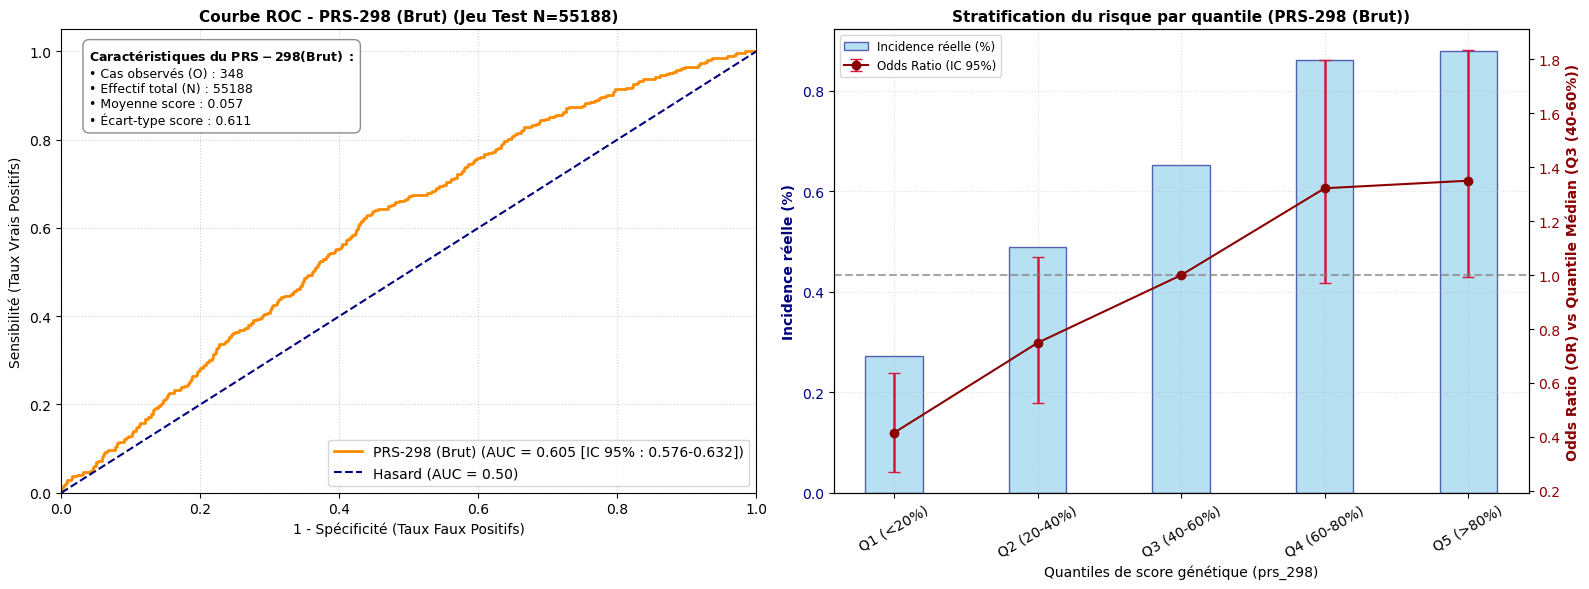

In [15]:
metrics_298, df_eval_298 = evaluate_and_plot_raw_prs(
    df_data=df_models,
    test_ids=test_ids_eur,
    prs_col="prs_298",
    model_name="PRS-298 (Brut)",
)

### Calcul du alpha recalibré sur le train set (25%)

1. Le problème du biais de sur-optimisation (Data Leakage)

Au point 2, tu calcules `prs_prob_recalib` directement sur tout le dataframe `df_models`.
* Problème : Si `df_models` contient à la fois le Train (25%) et le Test (75%), réinjecter la probabilité réétalonnée globale risque d'introduire des biais lors des analyses ultérieures.
* Bonne pratique : Applique la transformation uniquement sur le jeu de Test (75%) pour évaluer la calibration sur des données totalement indépendantes.

2. Le contrôle de l'âge à l'inclusion / temps de suivi

Une régression logistique simple $Y \sim \text{PRS}$ sur une cohorte d'âge hétérogène ($40\text{--}74$ ans) suppose que toutes les femmes ont le même risque de base, ce qui est faux.
* Ajustement : Il est recommandé d'inclure au minimum l'âge à l'inclusion (ou l'âge de référence $T_{\text{réf}}$) comme covariable dans l'apprentissage de la recalibration, ou d'utiliser un modèle avec offset pour caler l'intercept sur l'incidence de la tranche d'âge.

3. La vérification du recentrage du Z-scoreAvant de passer prs_298 dans la régression logistique, assure-toi que ton PRS a bien été centré-réduit ($\mu = 0, \sigma = 1$) sur la population témoin ($Y=0$) du jeu Train. Si le score Z brut dévie légèrement (ex. $\mu = 0{,}12$), l'intercept $\alpha$ absorbant cette déviation sera légèrement décalé.

In [20]:
df_models, params_298 = recalibrate_prs_model(
    df_data=df_models,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_298",
)

=== RECALIBRATION : PRS_298 ===
• Normalisation (Témoins Train) : μ = 0.0503, σ = 0.6123
• Coefficients appris (Train 25%) : Intercept (α) = -7.8562, Pente PRS (β) = 0.2922, Pente Âge = 0.0458
• Probabilités générées : Colonne 'prs_298_prob_recalib' (N Test = 55188)



Ces paramètres sont très cohérents avec la théorie biostatistique :

* $\mu = 0{,}0503 \approx 0$ : La moyenne des témoins est très proche de zéro, ce qui confirme que la distribution brute du PRS dans ta population contrôle était déjà globalement bien centrée.
* $\sigma = 0{,}6123 \neq 1$ : L'écart-type est inférieur à $1$, ce qui montre que la variance brute du PRS dans la cohorte est plus resserrée que celle de la population source (UK Biobank / BCAC).
*
* Cette étape de recentrage est donc pleinement justifiée : en divisant par $\sigma = 0{,}6123$, tu restructures l'échelle pour qu'un écart de $+1$ unité de `prs_298_z` corresponde exactement à $+1$ écart-type de risque génétique chez les témoins.

### Evaluation après recalibration

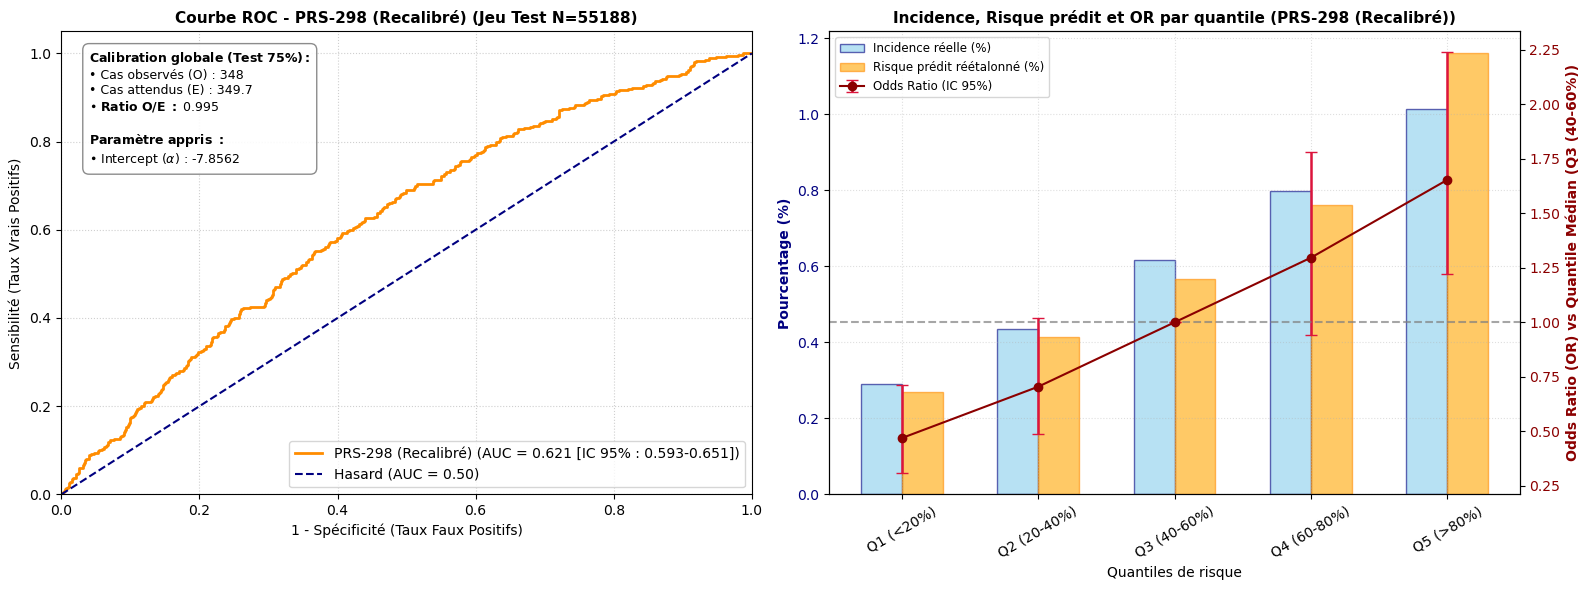

In [30]:
metrics_298, df_eval_298 = evaluate_and_plot_model(
    df_data=df_models,
    test_ids=test_ids_eur,
    score_col=params_298["recalib_col"],  # 'prs_298_prob_recalib'
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-298 (Recalibré)",
    alpha_val=params_298["alpha"],
)

**Pourquoi le ratio $O/E$ réapparaît maintenant ?**

* **Sur le PRS brut alone :** Tu as raison, le ratio $O/E$ n'existe pas car un Z-score ou un Risk Ratio relatif n'est pas une probabilité. On ne peut pas sommer des Z-scores pour obtenir un « nombre de cas attendus ». C'est pour cela que la fonction `evaluate_and_plot_raw_prs` ne contenait aucun ratio $O/E$.
* **Après la fonction `recalibrate_prs_model` :** La régression logistique bivariée ($Y \sim \text{PRS}_z + \text{Âge}$) a transformé le Z-score en une probabilité absolue de maladie ($\hat{p} \in [0, 1]$) stockée dans prs_298_prob_recalib.
* **Sur les probabilités absolues :** Une fois converti en probabilité, le score prend la même forme mathématique qu'un modèle clinique (comme Mammorisk ou BCSC). Il devient alors possible et pertinent de calculer $E = \sum \hat{p}_i$ et d'afficher le ratio $O/E$ pour vérifier si le modèle logistique est bien calé sur l'incidence globale du jeu de test.

**La distinction clé à retenir**

* **PRS Brut (`prs_298`) :** Score relatif ($Z$). Pas de probabilité absolue, donc pas de métrique $O/E$ (on évalue uniquement l'AUC et les Odds Ratios par quintile via `evaluate_and_plot_raw_prs`).
* **PRS Recalibré (`prs_298_prob_recalib`) :** Probabilité absolue réétalonnée. La métrique $O/E$ devient valide et indispensable pour vérifier que la recalibration logistique a fonctionné ($O/E \approx 1{,}00$).

* Ton intuition était parfaite : le PRS pur n'a pas de $O/E$, c'est l'étape de conversion logistique en probabilité qui lui donne une échelle absolue sur laquelle le $O/E$ prend tout son sens.

## PRS 305

### Evaluation brut

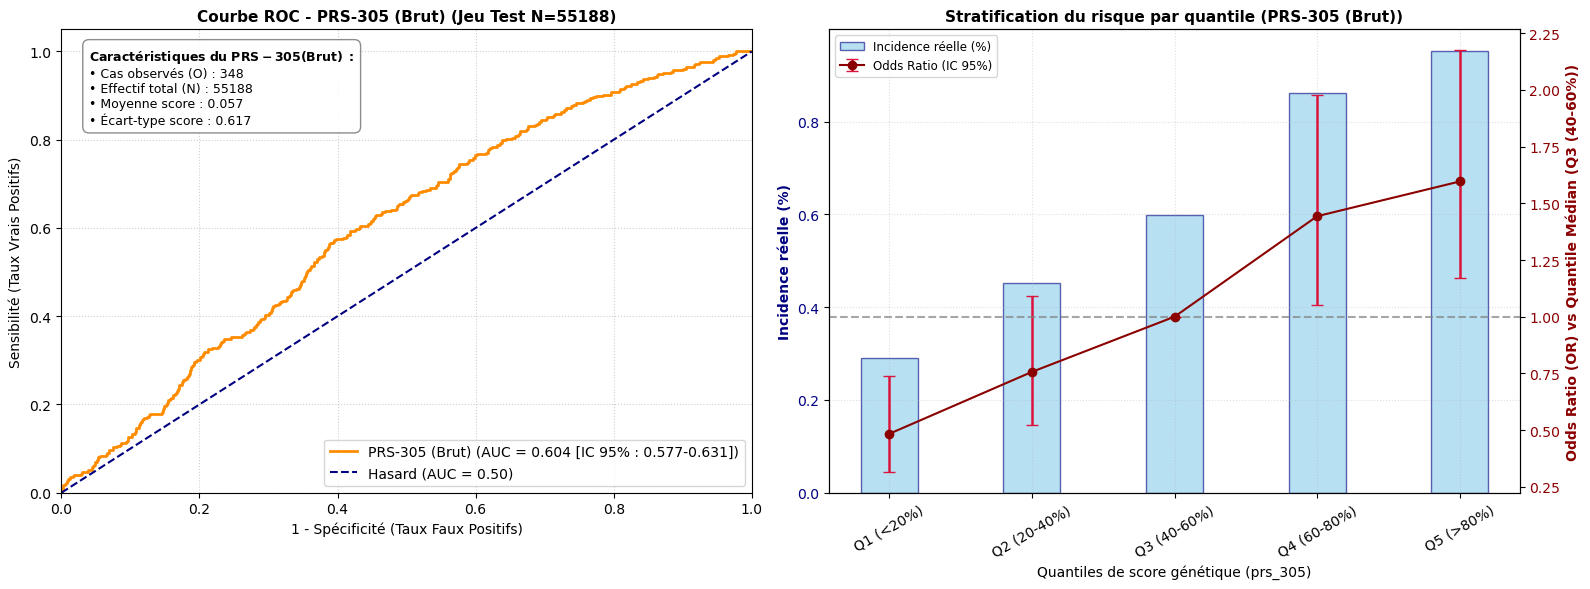

In [35]:
metrics_305, df_eval_305 = evaluate_and_plot_raw_prs(
    df_data=df_models,
    test_ids=test_ids_eur,
    prs_col="prs_305",
    model_name="PRS-305 (Brut)",
)

### Calcul du alpha recalibré sur le train set (25%)

In [36]:
df_models, params_305 = recalibrate_prs_model(
    df_data=df_models,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_305",
)

=== RECALIBRATION : PRS_305 ===
• Normalisation (Témoins Train) : μ = 0.0499, σ = 0.6183
• Coefficients appris (Train 25%) : Intercept (α) = -7.8582, Pente PRS (β) = 0.2963, Pente Âge = 0.0458
• Probabilités générées : Colonne 'prs_305_prob_recalib' (N Test = 55188)



### Evaluation après recalibration

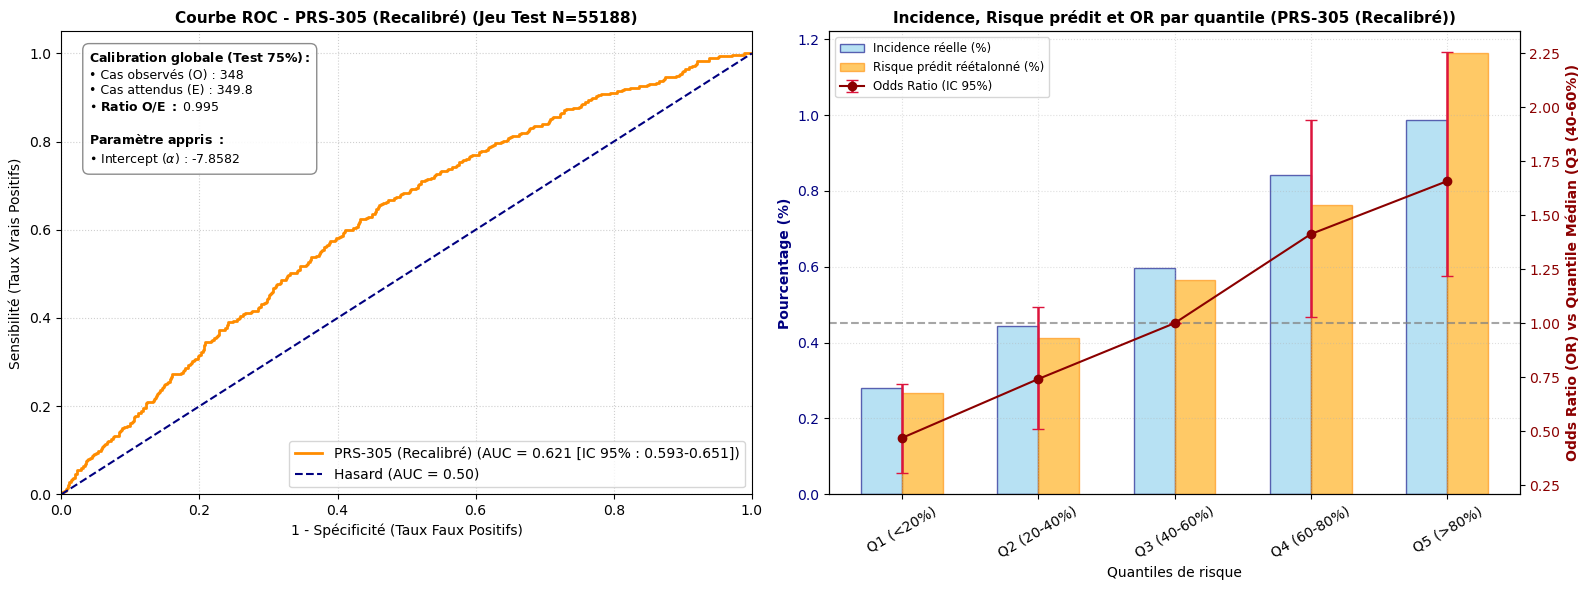

In [37]:
metrics_305, df_eval_305 = evaluate_and_plot_model(
    df_data=df_models,
    test_ids=test_ids_eur,
    score_col=params_305["recalib_col"],  # 'prs_298_prob_recalib'
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-305 (Recalibré)",
    alpha_val=params_305["alpha"],
)

## PRS 311

### Evaluation brut

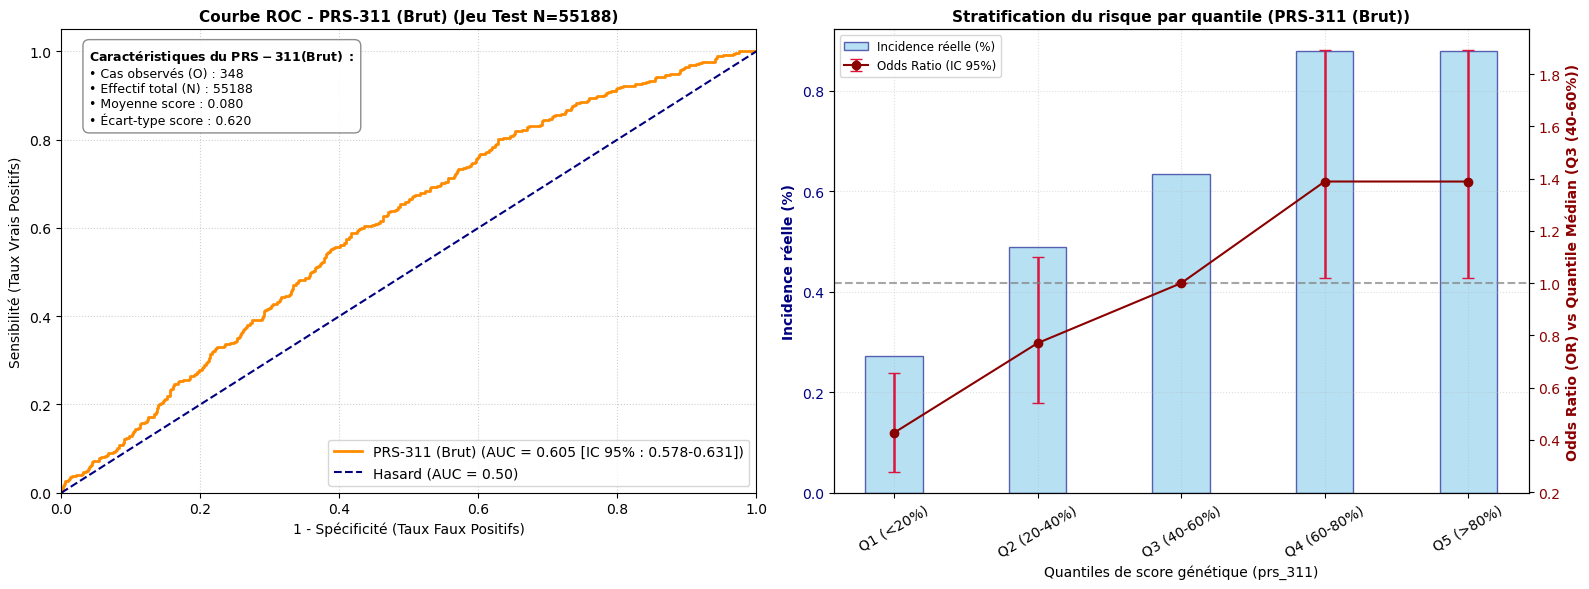

In [39]:
metrics_311, df_eval_311 = evaluate_and_plot_raw_prs(
    df_data=df_models,
    test_ids=test_ids_eur,
    prs_col="prs_311",
    model_name="PRS-311 (Brut)",
)

### Calcul du alpha recalibré sur le train set (25%)

In [40]:
df_models, params_311 = recalibrate_prs_model(
    df_data=df_models,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    prs_col="prs_311",
)

=== RECALIBRATION : PRS_311 ===
• Normalisation (Témoins Train) : μ = 0.0729, σ = 0.6209
• Coefficients appris (Train 25%) : Intercept (α) = -7.8573, Pente PRS (β) = 0.2880, Pente Âge = 0.0458
• Probabilités générées : Colonne 'prs_311_prob_recalib' (N Test = 55188)



### Evaluation après recalibration

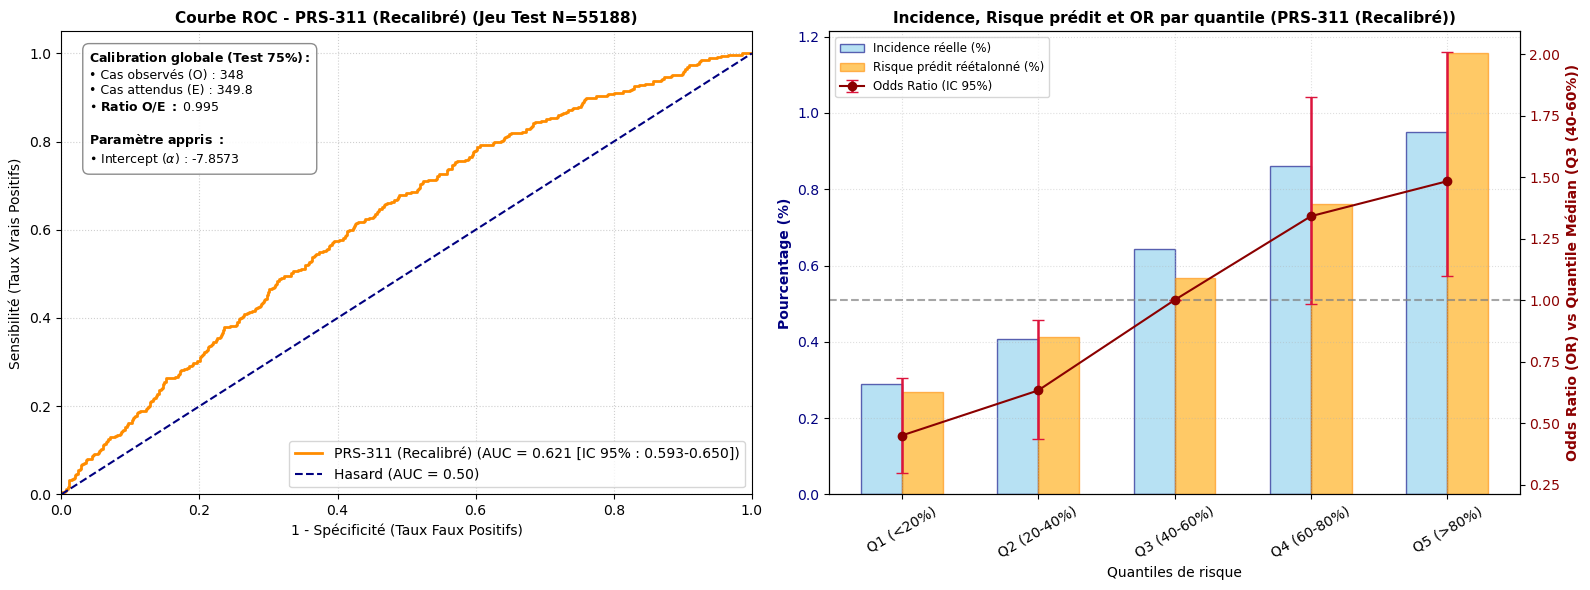

In [41]:
metrics_311, df_eval_311 = evaluate_and_plot_model(
    df_data=df_models,
    test_ids=test_ids_eur,
    score_col=params_311["recalib_col"],  # 'prs_298_prob_recalib'
    target_col="has_bc",
    id_col="person_id",
    model_name="PRS-311 (Recalibré)",
    alpha_val=params_311["alpha"],
)